This is the cutdown companion Jupyter Notebook of Chapter 6, Noise in Quantum Computation, of the second edition of the book titled: "Quantum Chemistry and Computing for the Curious: Illustrated with Python and Qiskit® code" and with ISBN-13: 978-1803243900. Copyright © 2026, Keeper L. Sharkey and Alain Chancé.

The following MIT license only applies to the code, and not to the text and images. The authors are not granting a license to replicate or reuse the text and images in the companion Jupyter notebook.

# MIT License

Copyright (c) 2026 Packt

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.

# 6. Noise in Quantum Computation

# Technical requirements
A companion Jupyter notebook for this chapter can be downloaded from GitHub at  https://github.com/PacktPublishing/Quantum-Chemistry-and-Computing-for-the-Curious-Second-Edition. For more information about how to install Qiskit, please refer to the IBM Install Qiskit documentation, https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit, and in Robert Loredo's book [Loredo_Qiskit].

The companion Jupyter notebook automatically installs the following list of libraries:
The companion Jupyter notebook automatically installs the following list of libraries:
* Numerical Python (NumPy) [NumPy], an open-source Python library that is used in almost every field of science and engineering.
* Qiskit [Qiskit], an open-source SDK for working with quantum computers at the level of pulses, circuits, and application modules.
* Qiskit Runtime IBM Client provides the interface to access the Qiskit Runtime service on IBM Quantum Platform.
* Qiskit visualization support to enable the use of visualizations and Jupyter notebooks.
* Qiskit Nature [Qiskit_Nature] [Qiskit_Nat_0], a unique platform to bridge the gap between natural sciences and quantum simulations.
* Python-based Simulations of Chemistry Framework (PySCF) [PySCF], an open-source collection of electronic structure modules powered by Python.
* Quantum Toolbox in Python (QuTiP) [QuTiP], a general framework for solving quantum mechanics problems such as systems composed of few-level quantum systems and harmonic oscillators.
* Atomic Simulation Environment (ASE) [ASE_0], a set of tools and Python modules for setting up, manipulating, running, visualizing, and analyzing atomistic simulations. The code is freely available under the GNU LGPL license.
* PyQMC [PyQMC], a Python module that implements real-space quantum Monte Carlo techniques. It is primarily meant to interoperate with PySCF.
* h5py [h5py] package, a Pythonic interface to the HDF5 binary data format.
* SciPy [SciPy], a Python module that contains a large number of probability distributions, summary and frequency statistics, correlation functions and statistical tests, masked statistics, kernel density estimation, quasi-Monte Carlo functionality, and more.
* scikit-learn, (often written sklearn) is a widely used open-source Python library for machine learning. It provides efficient and easy-to-use tools for building, training, and evaluating machine-learning models.


# New in the second edition
## New run_vqe_with_noise() function

## Installing NumPy, and Qiskit and importing various modules
### Install NumPy with the following command:

In [1]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit with the following command:

In [2]:
pip install qiskit

Note: you may need to restart the kernel to use updated packages.


### Install the IBM Runtime client

In [3]:
pip install qiskit-ibm-runtime

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit visualization support with the following command:

In [4]:
pip install 'qiskit[visualization]'

Note: you may need to restart the kernel to use updated packages.


## Install Qiskit Aer with the following command:

In [5]:
pip install qiskit-aer

Note: you may need to restart the kernel to use updated packages.


### Install qiskit.utils with the following command:

In [6]:
pip install qiskit.utils

Note: you may need to restart the kernel to use updated packages.


### Install Qiskit Nature with the following command:

In [7]:
pip install qiskit-nature

Note: you may need to restart the kernel to use updated packages.


## Temporary fix in Qiskit Nature file qeom.py - Use at your own risk

In [8]:
#----------------------------------------------------------------------------------------------------
# Temporary fix in Qiskit Nature file qeom.py — Use at your own risk.
#
# **Warning**
# Like any other Apache 2 licensed code, you are free to use `qiskit_algorithms` and `qiskit_nature` 
# libraries or/and extend them, but please be aware that it is under your own risk. 
# See disclaimer in readme,
# https://github.com/qiskit-community/qiskit-algorithms?tab=readme-ov-file#qiskit-algorithms
#
# In Qiskit 2.x, BaseEstimator no longer exists.
#
# The following snippet tries to execute the following command:
# 
#   from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver
# 
# If it fails, then it tries to comment out the following line:
# 
#   from qiskit.primitives import BaseEstimator
# 
# in the following file, if it can find it:
#
# qiskit_nature/second_q/algorithms/excited_states_solvers/qeom.py`
#----------------------------------------------------------------------------------------------------
apply_patch = False
try:
    from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver
except Exception as e:
    print(f"Error trying import GroundStateEigensolver: {e}")
    apply_patch = True

if apply_patch:
    import os
    import site
    import re
    from pathlib import Path
    
    sitepackages = site.getsitepackages()
    path = Path(sitepackages[0]) / "qiskit_nature" / "second_q" / "algorithms" / "excited_states_solvers" / "qeom.py"
    
    if os.path.isfile(path):
        text = path.read_text()
        pattern = r"^\s*from qiskit\.primitives import BaseEstimator\s*$"
        
        if re.search(pattern, text, flags=re.MULTILINE):
            print("Patching qeom.py...")
            text = re.sub(
                pattern,
                "# from qiskit.primitives import BaseEstimator",
                text,
                flags=re.MULTILINE
            )
            path.write_text(text)
            print("Patch applied ✅")
        else:
            print("Patch already applied or line not found 👍")

### Install Qiskit Algorithms with the following command:

In [9]:
pip install qiskit_algorithms

Note: you may need to restart the kernel to use updated packages.


### Install PySCF with the following command:

In [10]:
pip install pyscf

Note: you may need to restart the kernel to use updated packages.


### Install QuTiP with the following command:

In [11]:
pip install qutip

Note: you may need to restart the kernel to use updated packages.


### Install ASE with the following command:

In [ ]:
pip install ase

### Install PyQMC with the following command:

In [12]:
pip install pyqmc --upgrade

Note: you may need to restart the kernel to use updated packages.


### Install h5py with the following command:

In [13]:
pip install h5py

Note: you may need to restart the kernel to use updated packages.


### Install SciPy with the following command:

In [14]:
pip install scipy

Note: you may need to restart the kernel to use updated packages.


### Install scikit-learn with the following command:

In [15]:
pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


### Import Qiskit Runtime primitives with the following commands:

In [16]:
# Import Qiskit Runtime primitives
from qiskit.primitives import BaseSamplerV2 as BaseSampler, StatevectorSampler as Sampler
from qiskit.primitives import BaseEstimatorV2 as BaseEstimator, StatevectorEstimator as Estimator

### Import the required functions and class methods with the following commands:

In [17]:
from qiskit.visualization import array_to_latex, plot_bloch_vector, plot_bloch_multivector, plot_state_qsphere, plot_state_city
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
import qiskit.quantum_info as qi
from qiskit.circuit.library import Initialize
from qiskit.quantum_info import SparsePauliOp

from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

### Import Qiskit Aer simulator and NoiseModel class with the following commands:

In [18]:
import qiskit_aer
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, pauli_error
from qiskit.result import Counts

### Import the Qiskit Nature libraries with the following commands:

In [19]:
from qiskit_nature.second_q.formats.molecule_info import MoleculeInfo
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver

from qiskit_nature.second_q.mappers import ParityMapper, JordanWignerMapper, BravyiKitaevMapper
from qiskit_nature.second_q.properties import ParticleNumber
from qiskit_nature.second_q.transformers import ActiveSpaceTransformer, FreezeCoreTransformer
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_nature.second_q.operators import ElectronicIntegrals

from qiskit_nature import settings

### Import various algorithms with the following commands:

In [20]:
from qiskit_algorithms import PhaseEstimation

from qiskit_algorithms.optimizers import ADAM, COBYLA, L_BFGS_B, NELDER_MEAD, SPSA, SLSQP, QNSPSA
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock

from qiskit_algorithms.minimum_eigensolvers import NumPyMinimumEigensolver, VQE
from qiskit_nature.second_q.algorithms.ground_state_solvers import GroundStateEigensolver

from qiskit.circuit.library import n_local
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp

from functools import partial as apply_variation

### Import the PySCF gto and scf libraries with the following command:

In [21]:
from pyscf import gto, scf

### Import the math libraries with the following commands:

In [22]:
import cmath
import math

### Import time and datetime with the following command:

In [23]:
import time, datetime

### Import pandas and os.path with the following commands:

In [24]:
import pandas as pd
import os.path

### Import NumPy with the following command:

In [25]:
import numpy as np
from numpy.polynomial.polynomial import Polynomial

### Import Matplotlib with the following command:

In [26]:
import matplotlib.pyplot as plt

### Import LinearRegression from scikit-learn

In [27]:
from sklearn.linear_model import LinearRegression

### Import warnings and ignore Sparse Efficiency Warning

In [28]:
import warnings
from scipy.sparse import SparseEfficiencyWarning

warnings.filterwarnings("ignore", category=SparseEfficiencyWarning)

# 6.1. Introduction to Noisy Intermediate-Scale Quantum Devices

# 6.2. Building Noise Models in Python with Qiskit Aer

# 6.3. Error Mitigation Techniques

## 6.3.1. Zero-Noise Extrapolation (ZNE)

### Python implementation of ZNE using Qiskit, Qiskit Aer with a noise model and NumPy

In [29]:
# Simple circuit: prepare |1> and measure Z
qc = QuantumCircuit(1)
qc.x(0)
qc.measure_all()

In [30]:
def make_noise_model(scale):
    noise = NoiseModel()
    p = scale * p_base
    error = depolarizing_error(p, 1)
    noise.add_all_qubit_quantum_error(error, ['x', 'id'])
    return noise

In [31]:
# Setup the base noise model
p_base = 0.05

# Initialize the scales and expectations
scales = [1, 2, 3]
expectations = []

# Run circuit at different noise scale factors
for s in scales:
    backend = AerSimulator(
        # Using method='density_matrix' (or 'automatic') ensures the noise model is applied
        method='density_matrix',
        noise_model=make_noise_model(s)
    )
    job = backend.run(qc, shots=2000)
    result = job.result()
    counts = result.get_counts()

    p0 = counts.get('0', 0) / 2000
    p1 = counts.get('1', 0) / 2000
    # Using Z = P(0) - P(1) as the observable
    exp = p0 - p1
    expectations.append(exp)

# Linear fit of the expectations
poly = Polynomial.fit(scales, expectations, deg=1)

# Evaluate the fit at s=0 to get ZNE estimate
zne_value = poly(0)

print("Noise scales:", scales)
print(f"Expectations: {[f'{x:5.3f}' for x in expectations]}")
print(f"ZNE extrapolated value at zero noise: {zne_value:5.3f}")

Noise scales: [1, 2, 3]
Expectations: ['-0.948', '-0.892', '-0.848']
ZNE extrapolated value at zero noise: -0.996


### Plotting the noisy points and the extrapolated line

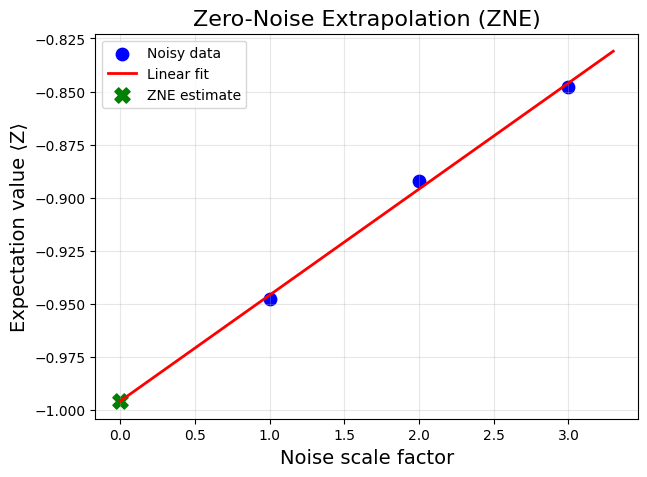

ZNE extrapolated value at zero noise: -0.996


In [32]:
# Fit a linear polynomial
poly = Polynomial.fit(scales, expectations, deg=1)
zne_value = poly(0)

# Generate smooth x-values for plotting the extrapolation line
x_fit = np.linspace(0, max(scales) * 1.1, 200)
y_fit = poly(x_fit)

# Plot
plt.figure(figsize=(7, 5))

# Noisy data points
plt.scatter(scales, expectations, color='blue', s=80, label='Noisy data')

# Extrapolation line
plt.plot(x_fit, y_fit, color='red', linewidth=2, label='Linear fit')

# Zero-noise estimate marker
plt.scatter([0], [zne_value], color='green', s=120, marker='X', label='ZNE estimate')

# Labels and formatting
plt.xlabel("Noise scale factor", fontsize=14)
plt.ylabel("Expectation value ⟨Z⟩", fontsize=14)
plt.title("Zero-Noise Extrapolation (ZNE)", fontsize=16)
plt.grid(alpha=0.3)
plt.legend()

# Save and show
fig_name = "Figure_6_2 - Zero_Noise Extrapolation"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

print(f"ZNE extrapolated value at zero noise: {zne_value:5.3f}")

### Case study: H2 ground state improvement via ZNE

In [33]:
#from utils_1_0 import create_tl_circuit, get_particle_number, fermion_to_qubit, H2_moleculeinfo

In [ ]:
# We set a heuristic ansatz, the Two-Local circuit [Panagiotis].
def create_tl_circuit(num_qubits):
    tl_circuit = n_local(
        num_qubits=num_qubits,   # REQUIRED now
        rotation_blocks=['h', 'rx'],
        entanglement_blocks='cz',
        entanglement='full',
        reps=2,
        parameter_prefix='y'
    )
    return tl_circuit

In [ ]:
# ## Define function get_particle_number()
# We use the get_particle_number() function defined in Section 4.6.1, Constructing a fermionic Hamiltonian operator of the hydrogen molecule, which gets the particle number property of a given electronic structure problem.
def get_particle_number(problem, show=True):
  # https://qiskit.org/documentation/nature/stubs/qiskit_nature.second_q.problems.ElectronicStructureProblem.num_spin_orbitals.html
  num_spin_orbitals = problem.num_spin_orbitals
  num_particles = problem.num_particles
  if show:
    print("Number of particles: {}".format(num_particles))
    print("Number of spin orbitals: {}".format(num_spin_orbitals))
  return num_particles, num_spin_orbitals

In [ ]:
# ## Define function fermion_to_qubit()
# We use the fermion_to_qubit() function defined in Section 4.8, Constructing a qubit Hamiltonian with Qiskit Nature to convert a fermionic operator to a qubit operator. It has the following input parameters:
# - second_q_op, a fermionic operator obtained as explained in Section 4.6, Constructing a fermionic Hamiltonian with Qiskit Nature
# - mapper_name, either “Jordan-Wigner” or “Parity” or “Bravyi-Kitaev”
# - truncate, an integer to truncate Pauli list by default set to 20 items
# - two_qubit_reduction, a Boolean, by default False, that determines whether to carry out two-qubit reduction when possible
# - z2symmetry_reduction, by default None, that indicates whether a Z2 symmetry reduction should be applied to resulting qubit operators that are computed based on mathematical symmetries that can be detected in the operator [de Keijzer]
# - show, set to True by default to display the name of the transformation and results
# 
# Here is the code:
def fermion_to_qubit(problem, 
                     second_q_op,
                     mapper_name,
                     truncate=20,
                     two_qubit_reduction=False,
                     z2symmetry_reduction=None,
                     show=True): 
  if show:
    print("Qubit Hamiltonian operator")
    print("{} transformation ". format(mapper_name))

  match mapper_name:
    case "Jordan-Wigner":
      mapper = JordanWignerMapper()
    case "Parity":
      mapper = ParityMapper(num_particles=problem.num_particles)
    case "Bravyi-Kitaev":
      mapper = BravyiKitaevMapper()
  
  qubit_op = mapper.map(second_q_op)
  
  if z2symmetry_reduction != None:
    tapered_mapper = problem.get_tapered_mapper(mapper)
    qubit_op = tapered_mapper.map(second_q_op)
    mapper = tapered_mapper 
    
  n_items = len(qubit_op)
  if show:
    print("Number of items in the Pauli list:", n_items)
    if n_items <= truncate:
      print(qubit_op)
    else:
      print(qubit_op[0:truncate])
  return qubit_op, mapper

In [ ]:
# ## Define the molecular geometry of the hydrogen molecule
# We follow the process described in Section 4.6.1, Constructing a fermionic Hamiltonian operator of the hydrogen molecule. We define the molecular geometry of the hydrogen molecule as follows:

H2_atoms = ["H", "H"]
H2_coords = [(0.0, 0.0, 0.0), (0.0, 0.0, 0.735)]
H2_charge = 0
H2_multiplicity = 1
H2_atom_pair=(1, 0)
H2_info_dict={'atoms':H2_atoms, 'coords':H2_coords, 'charge':H2_charge, 'multiplicity':H2_multiplicity, 'atom_pair':H2_atom_pair}

H2_moleculeinfo = MoleculeInfo(H2_atoms, H2_coords, charge=H2_charge, multiplicity=H2_multiplicity)

In [34]:
def run_vqe_with_noise(
    name_solver,
    problem,
    mapper,
    num_qubits,
    maxiter=200,
    learning_rate=0.05,
    perturbation=0.5,
    optimizer=SPSA(maxiter=200),
    noise_model=None,
    show=False
):
    """Run VQE with noise, callback and return final energy + convergence history."""
    from qiskit_ibm_runtime import EstimatorV2 as Estimator
    from qiskit.primitives import StatevectorEstimator
    
    if noise_model is None:
        estimator = StatevectorEstimator()
    else:
         backend = AerSimulator(
            method='density_matrix',
            noise_model=noise_model
         )
         estimator = Estimator(mode=backend)

    history = []
    def qnspsa_callback(nfev, x, fx, stepsize, accepted):
        history.append(fx)

    def cb(eval_count, params, mean, std):
        history.append(float(np.real(mean)))
    
    match name_solver:
        case "NumPy exact solver":
            solver = NumPyMinimumEigensolver()
        case "vqe_tl_solver":
            ansatz = create_tl_circuit(num_qubits)
            solver = VQE(estimator=estimator, ansatz=ansatz, optimizer=optimizer, callback=cb)
        case "vqe_tl_QNSPSA_solver":
            ansatz = create_tl_circuit(num_qubits) 
            fidelity = QNSPSA.get_fidelity(ansatz, sampler=Sampler())
            qnspsa = QNSPSA(
                fidelity,
                maxiter=maxiter,
                learning_rate=learning_rate,
                perturbation=perturbation,
                callback=qnspsa_callback
            )
            solver = VQE(estimator=estimator, ansatz=ansatz, optimizer=qnspsa)
        case "UCCSD ansatz":
            ansatz = UCCSD(
                problem.num_spatial_orbitals,
                problem.num_particles,
                mapper,
                initial_state=HartreeFock(
                    problem.num_spatial_orbitals,
                    problem.num_particles,
                    mapper),
            )
            solver = VQE(estimator=estimator, ansatz=ansatz, optimizer=optimizer, callback=cb)
    
    calc = GroundStateEigensolver(mapper, solver)
    start = time.time()
    ground_state = calc.solve(problem)
    elapsed = str(datetime.timedelta(seconds = time.time()-start))
    
    if show:
        print(f"Running the VQE using the {name_solver}")
        print(f"Elapsed time: {elapsed}\n")
        print(ground_state)

    # Get the electronic ground-state energy
    E_elec = float(ground_state.electronic_energies[0])

    # Get the Total ground state energy (electronic + nuclear repulsion)
    Total_energy = float(ground_state.total_energies[0])
    
    return E_elec, Total_energy, history

In [35]:
def solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    mapper_name="Parity",
    two_qubit_reduction=True,
    z2symmetry_reduction=None,
    name_solver="vqe_tl_solver",
    maxiter=200,
    learning_rate=0.05,
    perturbation=0.5,
    optimizer = SPSA(maxiter=200),
    noise_model=None,
    show=False
) -> float:

    driver = PySCFDriver.from_molecule(moleculeinfo, basis="sto3g")

    # Define an electronic structure problem
    problem = driver.run()

    # Get the electronic energy fermionic Hamiltonian
    fermionic_hamiltonian = problem.hamiltonian
    second_q_op = fermionic_hamiltonian.second_q_op()

    # Get the number of particles and the number of spin orbitals
    num_particles, num_spin_orbitals = get_particle_number(problem, show=show)

    qubit_op, mapper = fermion_to_qubit(problem,
                                        second_q_op,
                                        mapper_name,
                                        two_qubit_reduction=two_qubit_reduction,
                                        z2symmetry_reduction=z2symmetry_reduction,
                                        show=show)

    # Get number of qubits
    num_qubits = qubit_op.num_qubits

    # Run VQE with noise
    E_elec, Total_energy, history = run_vqe_with_noise(
        name_solver,
        problem,
        mapper,
        num_qubits, 
        maxiter=maxiter,
        learning_rate=learning_rate,
        perturbation=perturbation,
        optimizer=optimizer,
        noise_model=noise_model,
        show=show)
    
    return E_elec, Total_energy, history

In [36]:
E_elec_ideal, Total_energy, history = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    optimizer=SPSA(maxiter=300),
    name_solver="vqe_tl_solver",
)
print(f"Ideal (noiseless) VQE electronic energy: {E_elec_ideal:.6f}")

Ideal (noiseless) VQE electronic energy: -1.857272


In [37]:
p_base_1q = 0.01
p_base_2q = 0.02

def make_noise_model(scale: float) -> NoiseModel:
    noise = NoiseModel()
    p1 = scale * p_base_1q
    p2 = scale * p_base_2q

    err1 = depolarizing_error(p1, 1)
    err2 = depolarizing_error(p2, 2)

    noise.add_all_qubit_quantum_error(err1, ['x', 'y', 'z', 'h', 'sx', 'id'])
    noise.add_all_qubit_quantum_error(err2, ['cx'])

    return noise

In [38]:
scales = [1.0, 2.0, 3.0]
energies = []

for s in scales:
    noise_model = make_noise_model(s)
    E_elec, Total_energy, history = solve_ground_state_with_noise(
        moleculeinfo=H2_moleculeinfo,
        optimizer=SPSA(maxiter=300),
        name_solver="vqe_tl_solver",
        noise_model=noise_model
    )
    energies.append(E_elec)
    print(f"Scale {s:.1f} → E = {E_elec:.6f}")

Scale 1.0 → E = -1.814683
Scale 2.0 → E = -1.785777
Scale 3.0 → E = -1.759537


In [39]:
poly = Polynomial.fit(scales, energies, deg=1)
E_zne = poly(0.0)

print()
print(f"Noisy electronic energies: {[f'{E_elec: .6f}' for E_elec in energies]}")
print(f"ZNE extrapolated electronic energy (s→0): {E_zne: .6f}")
print(f"Ideal noiseless electronic energy:        {E_elec_ideal: .6f}")


Noisy electronic energies: ['-1.814683', '-1.785777', '-1.759537']
ZNE extrapolated electronic energy (s→0): -1.841811
Ideal noiseless electronic energy:        -1.857272


## 6.3.2. Probabilistic Error Cancellation (PEC)

### Python demonstration with a 1‑qubit Hamiltonian

In [40]:
qc = QuantumCircuit(1)
qc.id(0)          # noise attaches here
qc.measure_all()

In [41]:
def expectation_Z_from_counts(counts):
    shots = sum(counts.values())
    p0 = counts.get('0', 0) / shots
    p1 = counts.get('1', 0) / shots
    return p0 - p1

In [42]:
backend = AerSimulator(method='density_matrix')
ideal_counts = backend.run(qc, shots=2000).result().get_counts()
ideal_Z = expectation_Z_from_counts(ideal_counts)
print(f"Ideal <Z>: {ideal_Z:6.3f}")

Ideal <Z>:  1.000


In [43]:
def make_bitflip_noise(p):
    noise = NoiseModel()
    error = pauli_error([('X', p), ('I', 1-p)])
    noise.add_all_qubit_quantum_error(error, ['id'])
    return noise

In [44]:
p = 0.2
backend_noisy = AerSimulator(method='density_matrix',
                             noise_model=make_bitflip_noise(p))
noisy_counts = backend_noisy.run(qc, shots=2000).result().get_counts()
noisy_Z = expectation_Z_from_counts(noisy_counts)
print(f"Noisy <Z>: {noisy_Z:6.3f}")

Noisy <Z>:  0.590


In [45]:
def inverse_quasiprobabilities(p):
    denom = 1 - 2*p
    alpha0 = 1.0 / denom
    alpha1 = -p / denom
    return alpha0, alpha1

In [46]:
rng = np.random.default_rng(1234)

def pec_estimate_Z(p, shots=8000):
    alpha0, alpha1 = inverse_quasiprobabilities(p)
    C = abs(alpha0) + abs(alpha1)
    q0 = abs(alpha0) / C
    q1 = abs(alpha1) / C

    estimates = []

    for _ in range(shots):
        # Sample inverse operation
        if rng.random() < q0:
            op = 'id'
            alpha = alpha0
        else:
            op = 'x'
            alpha = alpha1

        # Build effective circuit
        qc_eff = QuantumCircuit(1)
        if op == 'x':
            qc_eff.x(0)
        qc_eff.id(0)          # noise acts here
        qc_eff.measure_all()

        # Run with noise
        backend = AerSimulator(method='density_matrix',
                               noise_model=make_bitflip_noise(p))
        counts = backend.run(qc_eff, shots=1).result().get_counts()

        # Z expectation for this shot
        z_val = expectation_Z_from_counts(counts)

        # Weight
        w = np.sign(alpha) * C
        estimates.append(w * z_val)

    return np.mean(estimates)

In [47]:
pec_Z = pec_estimate_Z(p, shots=10000)
print(f"PEC    <Z>: {pec_Z:6.3f}")

PEC    <Z>:  1.196


## 6.3.3. Clifford Data Regression (CDR)

###	Python Illustration with Toy Pauli Expectations

In [48]:
def expectation_Z_from_counts(counts: Counts) -> float:
    shots = sum(counts.values())
    exp = 0
    for bitstring, c in counts.items():
        z = 1 if bitstring[-1] == '0' else -1
        exp += z * c
    return exp / shots

In [49]:
qc_target = QuantumCircuit(1)
qc_target.h(0)
qc_target.ry(0.7, 0)     # non-Clifford
qc_target.measure_all()

In [50]:
nshots = 8000

In [51]:
backend_ideal = AerSimulator(method="statevector", shots=nshots)
ideal_Z = expectation_Z_from_counts(
    backend_ideal.run(qc_target).result().get_counts()
)
print(f"Ideal <Z>: {ideal_Z: .3f}")

Ideal <Z>: -0.649


In [52]:
def make_depolarizing_noise(p):
    noise = NoiseModel()
    err = depolarizing_error(p, 1)
    noise.add_all_qubit_quantum_error(err, ['id', 'x', 'y', 'z', 'h', 'sx'])
    return noise

In [53]:
p = 0.15
backend_noisy = AerSimulator(method='density_matrix',
                             noise_model=make_depolarizing_noise(p))

noisy_Z = expectation_Z_from_counts(
    backend_noisy.run(qc_target, shots=nshots).result().get_counts()
)
print(f"Noisy <Z>: {noisy_Z: .3f}")

Noisy <Z>: -0.534


### Illustration of noisy observable fitting using Clifford circuits

In [54]:
training_circuits = []
exact_expectations = []

# |0>
qc0 = QuantumCircuit(1)
qc0.id(0)
qc0.measure_all()
training_circuits.append(qc0)
exact_expectations.append(1.0)

# |1>
qc1 = QuantumCircuit(1)
qc1.x(0)
qc1.measure_all()
training_circuits.append(qc1)
exact_expectations.append(-1.0)

# H (equator, 0)
qcH = QuantumCircuit(1)
qcH.h(0)
qcH.measure_all()
training_circuits.append(qcH)
exact_expectations.append(0.0)

In [55]:
noisy_training = []
for qc in training_circuits:
    counts = backend_noisy.run(qc, shots=nshots).result().get_counts()
    noisy_training.append(expectation_Z_from_counts(counts))

print("Noisy training:", noisy_training)
print("Exact training:", exact_expectations)

Noisy training: [0.8525, -0.84775, -0.00625]
Exact training: [1.0, -1.0, 0.0]


In [56]:
X = np.array(noisy_training).reshape(-1, 1)
y = np.array(exact_expectations)

reg = LinearRegression().fit(X, y)

cdr_corrected = reg.predict(np.array([[noisy_Z]]))[0]

print(f"CDR-corrected <Z>: {cdr_corrected: .3f}")

CDR-corrected <Z>: -0.628


### Plot showing the training fit, target, and ideal value

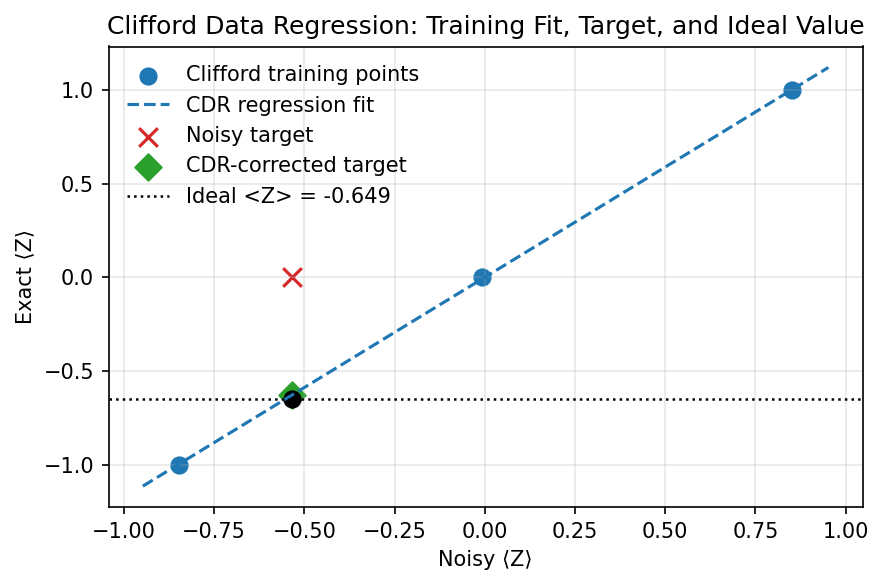

In [57]:
# Convert training data to arrays
X = np.array(noisy_training).reshape(-1, 1)
y = np.array(exact_expectations)

# Smooth regression line
x_line = np.linspace(min(noisy_training) - 0.1,
                     max(noisy_training) + 0.1, 200).reshape(-1, 1)
y_line = reg.predict(x_line)

plt.figure(figsize=(6, 4), dpi=150)

# Training points
plt.scatter(noisy_training, exact_expectations,
            color='tab:blue', s=60, label='Clifford training points')

# Regression line
plt.plot(x_line, y_line, color='tab:blue', linestyle='--',
         label='CDR regression fit')

# Noisy target point (plotted at y=0 baseline)
plt.scatter([noisy_Z], [0],
            color='tab:red', s=80, marker='x', label='Noisy target')

# CDR-corrected target point
plt.scatter([noisy_Z], [cdr_corrected],
            color='tab:green', s=80, marker='D', label='CDR-corrected target')

# Ideal value: horizontal line + marker
plt.axhline(ideal_Z, color='black', linestyle=':', linewidth=1.2,
            label=f'Ideal <Z> = {ideal_Z:.3f}')
plt.scatter([noisy_Z], [ideal_Z],
            color='black', s=60, marker='o')

plt.xlabel("Noisy ⟨Z⟩")
plt.ylabel("Exact ⟨Z⟩")
plt.title("Clifford Data Regression: Training Fit, Target, and Ideal Value")
plt.grid(alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()

fig_name = "CDR_Training_Fit"
plt.savefig(fig_name, dpi=150, bbox_inches='tight')
plt.show()

## 6.3.4. Measurement Error Mitigation (MEM)
###	Define a small test circuit that creates a Bell state

In [58]:
def counts_to_probvec(counts, n_qubits=2):
    shots = sum(counts.values())
    probs = np.zeros(2**n_qubits)
    for bitstring, c in counts.items():
        idx = int(bitstring, 2)
        probs[idx] = c / shots
    return probs

In [59]:
qc_test = QuantumCircuit(2)
qc_test.h(0)
qc_test.cx(0, 1)
qc_test.measure_all()

In [60]:
nshots = 10000

### Get the ideal probability distribution

In [61]:
backend_ideal = AerSimulator(shots=nshots)
ideal_counts = backend_ideal.run(qc_test).result().get_counts()
p_ideal = counts_to_probvec(ideal_counts, n_qubits=2)
print("Ideal probabilities:", p_ideal)

Ideal probabilities: [0.5006 0.     0.     0.4994]


### Define a measurement noise model (2-qubit)

In [62]:
def make_readout_noise(p):
    noise = NoiseModel()
    readout = [[1-p, p],
               [p, 1-p]]
    noise.add_readout_error(readout, [0])   # qubit 0
    noise.add_readout_error(readout, [1])   # qubit 1
    return noise

In [63]:
p = 0.2
backend_noisy = AerSimulator(noise_model=make_readout_noise(p))

In [64]:
result = backend_noisy.run(qc_test, shots=nshots).result()
noisy_counts = result.get_counts()
p_noisy = counts_to_probvec(noisy_counts, n_qubits=2)
print("Noisy probabilities:", p_noisy)

Noisy probabilities: [0.3353 0.1623 0.1631 0.3393]


### Build the 2‑qubit calibration circuits

In [65]:
cal_circuits = []
prep_states = ["00", "01", "10", "11"]

for state in prep_states:
    qc = QuantumCircuit(2)
    if state[1] == "1": qc.x(0)   # qubit 0 is least significant bit
    if state[0] == "1": qc.x(1)   # qubit 1 is most significant bit
    qc.measure_all()
    cal_circuits.append(qc)

### Run calibration circuits and build the 4×4 matrix

In [66]:
cal_matrix = []

for qc in cal_circuits:
    result = backend_noisy.run(qc, shots=nshots).result()
    counts = result.get_counts()
    probs = counts_to_probvec(counts, n_qubits=2)
    cal_matrix.append(probs)

A = np.array(cal_matrix)
print("Calibration matrix A:\n", A)

Calibration matrix A:
 [[0.6408 0.1597 0.1612 0.0383]
 [0.1613 0.6338 0.0441 0.1608]
 [0.1593 0.0423 0.6388 0.1596]
 [0.0396 0.1593 0.1551 0.646 ]]


###	Invert the calibration matrix

In [67]:
A_inv = np.linalg.inv(A)
print("Inverse calibration matrix A^{-1}:\n", A_inv)

Inverse calibration matrix A^{-1}:
 [[ 1.77671156 -0.447109   -0.44566268  0.11606012]
 [-0.44879818  1.79609964  0.09717744 -0.4444789 ]
 [-0.4401913   0.10252326  1.7758223  -0.43815426]
 [ 0.10744496 -0.44011535 -0.42300645  1.75567683]]


### Apply MEM to the noisy 2‑qubit circuit

In [68]:
p_corrected = A_inv @ p_noisy
p_corrected = np.clip(p_corrected, 0, 1)
p_corrected /= p_corrected.sum()
print("Corrected probabilities:", p_corrected)

Corrected probabilities: [0.49121358 0.00607968 0.01004199 0.49266475]


### Compare corrected probabilities with the ideal distribution

In [69]:
l1_noisy = np.sum(np.abs(p_noisy - p_ideal))
l1_corr  = np.sum(np.abs(p_corrected - p_ideal))

print("\nL1 noisy vs ideal:     {:.4f}".format(l1_noisy))
print("L1 corrected vs ideal: {:.4f}".format(l1_corr))

print("Noisy probabilities:     ", p_noisy)
print("Corrected probabilities: ", p_corrected)
print("Ideal probabilities:     ", p_ideal)

if l1_corr < l1_noisy:
    print("\nInverse calibration improved the estimate.")
else:
    print("\nInverse calibration did NOT improve the estimate.")


L1 noisy vs ideal:     0.6508
L1 corrected vs ideal: 0.0322
Noisy probabilities:      [0.3353 0.1623 0.1631 0.3393]
Corrected probabilities:  [0.49121358 0.00607968 0.01004199 0.49266475]
Ideal probabilities:      [0.5006 0.     0.     0.4994]

Inverse calibration improved the estimate.


# 6.4. Classical Optimizers in Noise-Aware Quantum Chemistry Computation
## 6.4.1. Role of Optimizers in Hybrid Quantum Algorithms
###	Why classical optimization is the bottleneck in NISQ chemistry
###	Optimizer–ansatz–noise interplay
###	Gradient-free vs gradient-based under noise

## 6.4.2. Survey of Common Optimizers (with Python examples)

In [70]:
def plot_history(hist, title):
    if not hist:
        return
    plt.figure(figsize=(6.2, 4.2))
    plt.plot(hist, marker='o', markersize=3, linewidth=1)
    plt.axhline(E_exact, color="k", linestyle="--", linewidth=1, label="Exact Energy")
    plt.xlabel("Iteration")
    plt.ylabel("Energy (Hartree)")
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    
    # Save and show
    fig_name = title.removeprefix("VQE Convergence —")
    plt.savefig(fig_name, dpi=150, bbox_inches='tight')
    plt.show()

In [71]:
results, histories = {}, {}

###	NumPy exact solver (exact classical reference)

In [72]:
E_exact, Total_energy, history = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="NumPy exact solver",
    noise_model=None
)

###	COBYLA (noise-resilient, good for small molecules)

In [73]:
E_cobyla, T_cobyla, hist_cobyla = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="UCCSD ansatz",
    optimizer=COBYLA(maxiter=200),
    noise_model=None
)
results["COBYLA"] = E_cobyla
histories["COBYLA"] = hist_cobyla

###	SLSQP (fast, smooth landscapes)

In [74]:
E_slsqp, T_slsqp, hist_slsqp = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="UCCSD ansatz",
    optimizer=SLSQP(maxiter=1000),
    noise_model=None
)
results["SLSQP"] = E_slsqp
histories["SLSQP"] = hist_slsqp

### L-BFGS-B  (quasi-Newton, efficient for near-convex landscapes)

In [75]:
E_l_bfgs_b, T_l_bfgs_b, hist_l_bfgs_b = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="UCCSD ansatz",
    optimizer=L_BFGS_B(maxiter=1000),
    noise_model=None
)
results["L-BFGS-B"] = E_l_bfgs_b
histories["L-BFGS-B"] = hist_l_bfgs_b 

###	NELDER–MEAD (fully gradient-free)

In [76]:
E_nelder_mead, T_nelder_mead, hist_nelder_mead = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="UCCSD ansatz",
    optimizer=NELDER_MEAD(maxiter=1000),
    noise_model=None
)
results["NELDER-MEAD"] = E_nelder_mead
histories["NELDER-MEAD"] = hist_nelder_mead 

###	ADAM (useful for variational quantum machine learning)

In [77]:
E_adam, T_adam, hist_adam = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="UCCSD ansatz",
    optimizer=ADAM(maxiter=10000, tol=1e-04),
    noise_model=None
)
results["ADAM"] = E_adam
histories["ADAM"] = hist_adam

###	SPSA (robust to noise, standard in VQE)

In [78]:
E_spsa, T_spsa, hist_spsa = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="UCCSD ansatz",
    optimizer=SPSA(maxiter=1000),
    noise_model=None
)
results["SPSA"] = E_spsa
histories["SPSA"] = hist_spsa

### QNSPSA (The Quantum Natural SPSA optimizer)

In [79]:
E_qnspsa, T_qnspsa, hist_qnspsa = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="vqe_tl_QNSPSA_solver",
    optimizer=None,
    learning_rate=0.05,
    perturbation=0.5,
    noise_model=None
)
results["QNSPSA"] = E_qnspsa
histories["QNSPSA"] = hist_qnspsa

In [80]:
print("\n=== Electronic Energy Comparison (Hartree) Noiseless ===")
print(f"Exact (NumPy):               {E_exact: .8f}")
print(f"VQE (COBYLA):                {results['COBYLA']: .8f}")
print(f"VQE (SLSQP):                 {results['SLSQP']: .8f}")
print(f"VQE (L-BFGS-B):              {results['L-BFGS-B']: .8f}")
print(f"VQE (NELDER-MEAD):           {results['NELDER-MEAD']: .8f}")
print(f"VQE (ADAM):                  {results['ADAM']: .8f}")
print(f"VQE (SPSA):                  {results['SPSA']: .8f}")
print(f"VQE (QNSPSA):                {results['QNSPSA']: .8f}")


=== Electronic Energy Comparison (Hartree) Noiseless ===
Exact (NumPy):               -1.85727503
VQE (COBYLA):                -1.85727503
VQE (SLSQP):                 -1.85727480
VQE (L-BFGS-B):              -1.85727503
VQE (NELDER-MEAD):           -1.85727502
VQE (ADAM):                  -1.85726747
VQE (SPSA):                  -1.85726794
VQE (QNSPSA):                -1.85725156


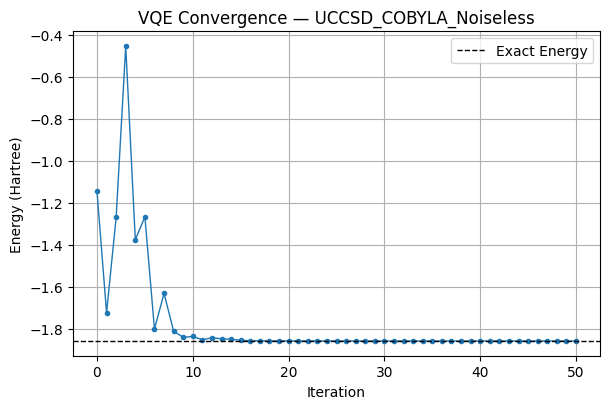

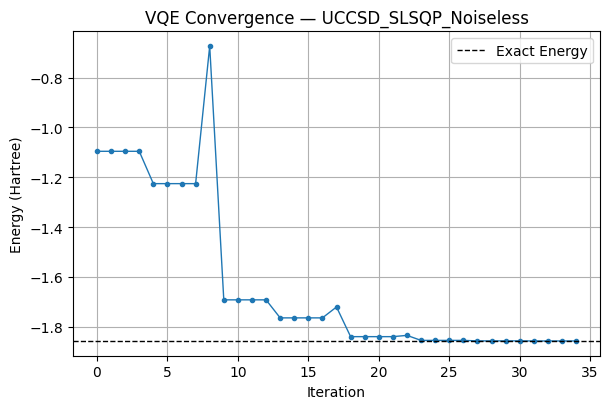

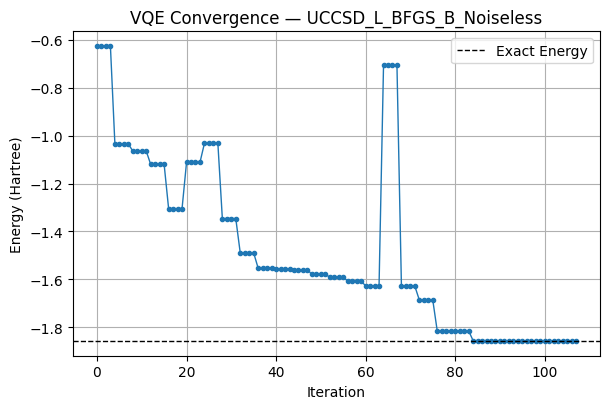

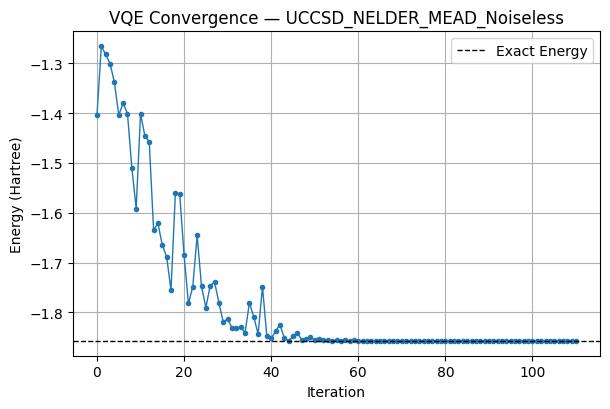

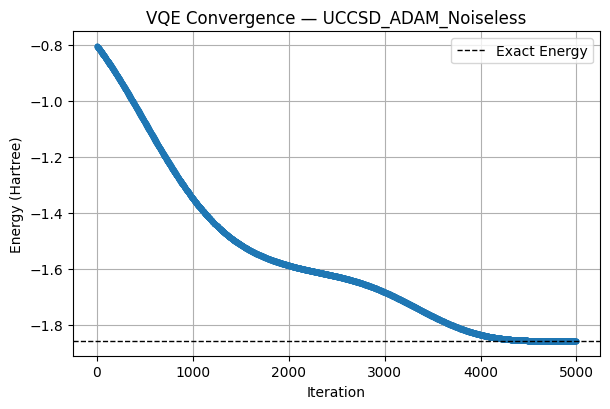

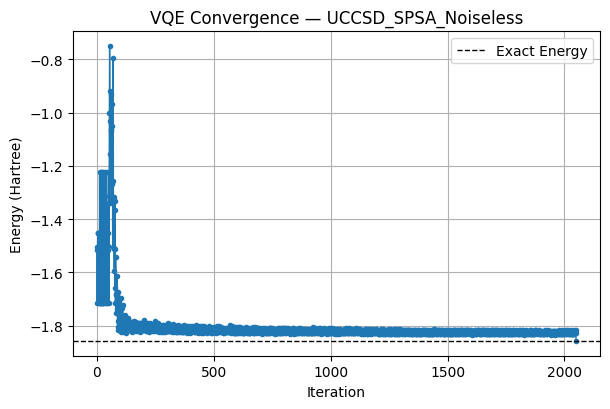

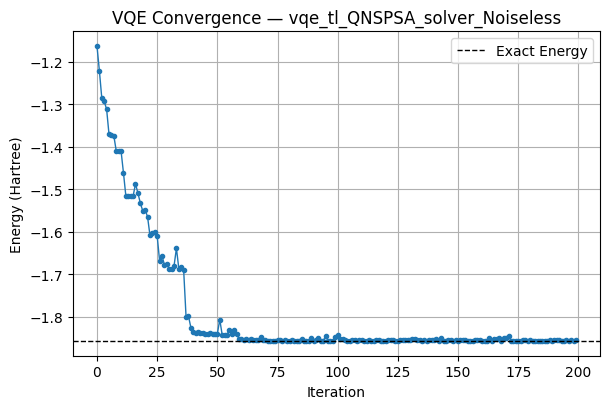

In [81]:
plot_history(hist_cobyla, "VQE Convergence — UCCSD_COBYLA_Noiseless")
plot_history(hist_slsqp, "VQE Convergence — UCCSD_SLSQP_Noiseless")
plot_history(hist_l_bfgs_b, "VQE Convergence — UCCSD_L_BFGS_B_Noiseless")
plot_history(hist_nelder_mead, "VQE Convergence — UCCSD_NELDER_MEAD_Noiseless")
plot_history(hist_adam, "VQE Convergence — UCCSD_ADAM_Noiseless")
plot_history(hist_spsa, "VQE Convergence — UCCSD_SPSA_Noiseless")
plot_history(hist_qnspsa, "VQE Convergence — vqe_tl_QNSPSA_solver_Noiseless")

## 6.4.3. How Noise Affects Optimizer Behavior
### Comparative behavior of VQE optimizers under noise
### Example of unstable behavior when optimizers see noisy gradients

In [82]:
noise_model = make_noise_model(0.1)

In [83]:
E_exact, Total_energy, history = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="NumPy exact solver",
    noise_model=noise_model
)

In [84]:
E_slsqp, T_slsqp, hist_slsqp = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="vqe_tl_solver",
    optimizer=SLSQP(maxiter=200),
    noise_model=noise_model
)
print(f"VQE (SLSQP with default finite difference step): {E_slsqp: .8f}")

VQE (SLSQP with default finite difference step): -0.83720060


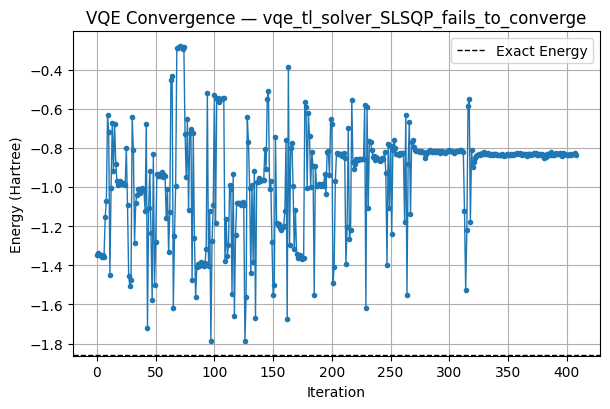

In [85]:
plot_history(hist_slsqp, "VQE Convergence — vqe_tl_solver_SLSQP_fails_to_converge")

### Python Side-by-Side Comparison

In [86]:
results, histories = {}, {}

E_slsqp, T_slsqp, hist_slsqp = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="vqe_tl_solver",
    # A larger eps makes the gradient signal larger than the noise.
    optimizer=SLSQP(maxiter=200, eps=1e-1),
    noise_model=noise_model
)
results["SLSQP"] = E_slsqp
histories["SLSQP"] = hist_slsqp

In [87]:
E_spsa, T_spsa, hist_spsa = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="vqe_tl_solver",
    optimizer=SPSA(maxiter=300),
    noise_model=noise_model
)
results["SPSA"] = E_spsa
histories["SPSA"] = hist_spsa

In [88]:
E_cobyla, T_cobyla, hist_cobyla = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="vqe_tl_solver",
    optimizer=COBYLA(maxiter=200),
    noise_model=noise_model
)
results["COBYLA"] = E_cobyla
histories["COBYLA"] = hist_cobyla

In [89]:
E_qnspsa, T_qnspsa, hist_qnspsa = solve_ground_state_with_noise(
    moleculeinfo=H2_moleculeinfo,
    name_solver="vqe_tl_QNSPSA_solver",
    optimizer=None,
    noise_model=noise_model
)
results["QNSPSA"] = E_qnspsa
histories["QNSPSA"] = hist_qnspsa

In [90]:
print("\n=== Electronic Energy Comparison (Hartree) Noise Model ===")
print(f"Exact (NumPy):               {E_exact: .8f}")
print(f"VQE (SLSQP):                 {results['SLSQP']: .8f}")
print(f"VQE (SPSA):                  {results['SPSA']: .8f}")
print(f"VQE (COBYLA):                {results['COBYLA']: .8f}")
print(f"VQE (QNSPSA):                {results['QNSPSA']: .8f}")


=== Electronic Energy Comparison (Hartree) Noise Model ===
Exact (NumPy):               -1.85727503
VQE (SLSQP):                 -1.84583606
VQE (SPSA):                  -1.84658658
VQE (COBYLA):                -1.85976531
VQE (QNSPSA):                -1.85389829


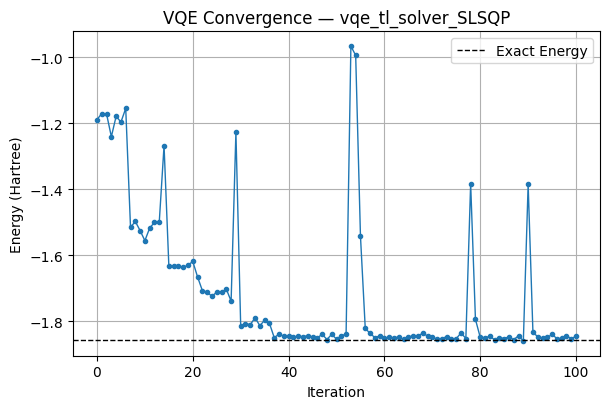

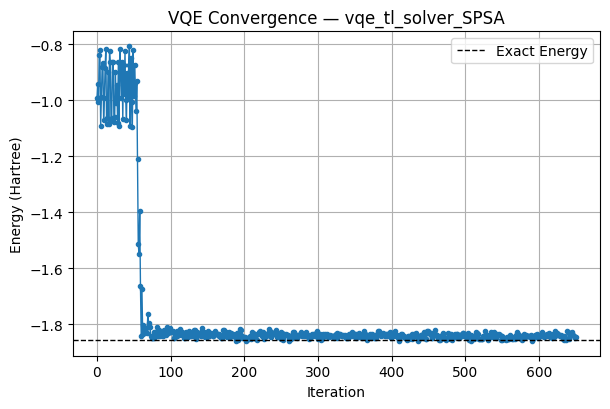

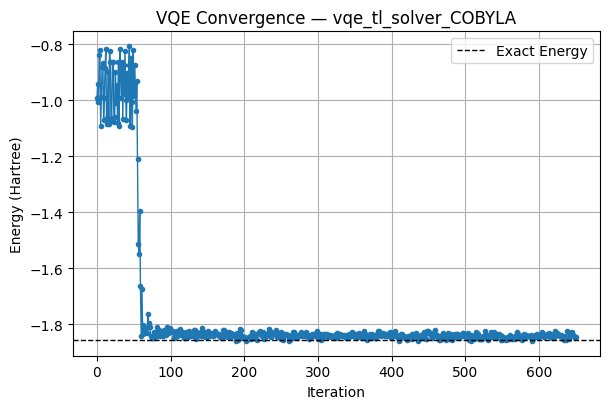

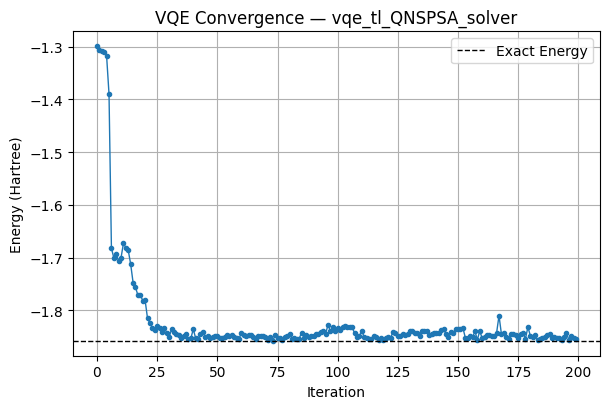

In [91]:
plot_history(hist_slsqp, "VQE Convergence — vqe_tl_solver_SLSQP")
plot_history(hist_spsa,  "VQE Convergence — vqe_tl_solver_SPSA")
plot_history(hist_spsa,  "VQE Convergence — vqe_tl_solver_COBYLA")
plot_history(hist_qnspsa, "VQE Convergence — vqe_tl_QNSPSA_solver")

# Conclusion

# References
[ASE_0] Atomic Simulation Environment (ASE), https://wiki.fysik.dtu.dk/ase/index.html

[H5py] Quick Start Guide, https://docs.h5py.org/en/stable/quick.html 

[Loredo_Qiskit] Robert Loredo, Chapter 3: Introducing and Installing Qiskit. Learn Quantum Computing with Python and IBM Quantum, Packt Publishing, 2025. ISBN 978-1803244808, https://www.amazon.fr/Learn-Quantum-Computing-Python-IBM/dp/1803244801/

[NumPy] NumPy: the absolute basics for beginners, https://numpy.org/doc/stable/user/absolute_beginners.html

[PyQMC] PyQMC, a python module that implements real-space quantum Monte Carlo techniques, https://github.com/WagnerGroup/pyqmc 

[PySCF] The Python-based Simulations of Chemistry Framework (PySCF), https://pyscf.org/

[Qiskit] Qiskit, https://qiskit.org/

[Qiskit_Aer_1] Qiskit Aer documentation, https://qiskit.github.io/qiskit-aer/ 

[Qiskit_Aer_2] NoiseModel, https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.NoiseModel.html 

[Qiskit_Nat_0] Qiskit_Nature, https://github.com/Qiskit/qiskit-nature/blob/main/README.md 

[Qiskit_Nature] Qiskit Nature overview, Qiskit Nature 0.7.2, https://qiskit-community.github.io/qiskit-nature/

[QuTiP] QuTiP, Plotting on the Bloch Sphere, https://qutip.readthedocs.io/en/qutip-5.0.x/guide/guide-bloch.html

[SciPy] Statistical functions (scipy.stats), https://projects.scipy.org/getting-started.html

[sklearn_PCA] Principal component analysis (PCA), https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html 

[sklearn_SVM] Support Vector Machines, https://scikit-learn.org/stable/auto_examples/svm/index.html 

[sklearn_SVR_1] Support Vector Regression (SVR) using linear and non-linear kernels, https://scikit-learn.org/stable/auto_examples/svm/plot_svm_regression.html 

[sklearn_SVR_2] SVR, Epsilon-Support Vector Regression, https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html 

## Qiskit packages versions

In [94]:
import qiskit
import qiskit_ibm_runtime
import qiskit_aer

print(f'Qiskit: {qiskit.__version__}')
print(f'Qiskit IBM Runtime: {qiskit_ibm_runtime.__version__}')
print(f"Qiskit Aer version: {qiskit_aer.__version__}")

Qiskit: 2.3.0
Qiskit IBM Runtime: 0.45.1
Qiskit Aer version: 0.17.2


## Qiskit Nature

In [95]:
import qiskit_nature
print(f"Qiskit Nature version: {qiskit_nature.__version__}")

Qiskit Nature version: 0.7.2


## Qiskit Algorithms

In [96]:
import qiskit_algorithms
print(f"Qiskit Algorithms version: {qiskit_algorithms.__version__}")

Qiskit Algorithms version: 0.4.0


## scikit-learn

In [97]:
import sklearn
sklearn.show_versions()


System:
    python: 3.13.12 | packaged by Anaconda, Inc. | (main, Feb 24 2026, 16:13:31) [GCC 14.3.0]
executable: /home/alain/miniconda3/bin/python3.13
   machine: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39

Python dependencies:
      sklearn: 1.8.0
          pip: 26.0.1
   setuptools: 80.10.2
        numpy: 2.3.5
        scipy: 1.17.1
       Cython: None
       pandas: 2.3.3
   matplotlib: 3.10.8
       joblib: 1.5.3
threadpoolctl: 3.6.0

Built with OpenMP: True

threadpoolctl info:
       user_api: blas
   internal_api: openblas
    num_threads: 22
         prefix: libopenblas
       filepath: /home/alain/miniconda3/lib/libopenblasp-r0.3.30.so
        version: 0.3.30
threading_layer: pthreads
   architecture: Haswell

       user_api: blas
   internal_api: openblas
    num_threads: 22
         prefix: libscipy_openblas
       filepath: /home/alain/miniconda3/lib/python3.13/site-packages/scipy.libs/libscipy_openblas-6cdc3b4a.so
        version: 0.3.30
threading_laye

## Python

In [98]:
# Display Python version
!python --version

Python 3.13.12
